# Alfido Tech — Task 2: Sales Performance Analysis

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

file_path = "superstore_final_dataset (1).csv"

# Load with automatic encoding fallback (Superstore CSVs often use latin1)
try:
    df = pd.read_csv(file_path, encoding="utf-8")
except UnicodeDecodeError:
    df = pd.read_csv(file_path, encoding="latin1")

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum()[df.isnull().sum() > 0])
print("\nExact Duplicates:", df.duplicated().sum())
df.head()

Shape: (9800, 18)

Columns: ['Row_ID', 'Order_ID', 'Order_Date', 'Ship_Date', 'Ship_Mode', 'Customer_ID', 'Customer_Name', 'Segment', 'Country', 'City', 'State', 'Postal_Code', 'Region', 'Product_ID', 'Category', 'Sub_Category', 'Product_Name', 'Sales']

Data Types:
 Row_ID             int64
Order_ID             str
Order_Date           str
Ship_Date            str
Ship_Mode            str
Customer_ID          str
Customer_Name        str
Segment              str
Country              str
City                 str
State                str
Postal_Code      float64
Region               str
Product_ID           str
Category             str
Sub_Category         str
Product_Name         str
Sales            float64
dtype: object

Missing Values:
 Postal_Code    11
dtype: int64

Exact Duplicates: 0


,Row_ID,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,City,State,Postal_Code,Region,Product_ID,Category,Sub_Category,Product_Name,Sales
0,1,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,8/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/6/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O Donnel,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold N Roll Cart System,22.3680


In [3]:
# 1. Inspect and fix the 11 missing Postal_Code entries
print("Missing Postal_Code cities:\n", df[df["Postal_Code"].isna()][["City", "State"]].value_counts())

# Fill missing Burlington, VT postal codes with 05401 (standard Superstore fix), fallback to "Unknown"
mask_burlington = df["Postal_Code"].isna() & (df["City"] == "Burlington") & (df["State"] == "Vermont")
df.loc[mask_burlington, "Postal_Code"] = 5401
df["Postal_Code"] = df["Postal_Code"].fillna(0).astype(int).astype(str).str.zfill(5)

# 2. Parse Order_Date and Ship_Date using dayfirst=True (DD/MM/YYYY format)
df["Order_Date"] = pd.to_datetime(df["Order_Date"], dayfirst=True)
df["Ship_Date"] = pd.to_datetime(df["Ship_Date"], dayfirst=True)

# 3. Feature Engineering
df["Year"] = df["Order_Date"].dt.year
df["Quarter"] = "Q" + df["Order_Date"].dt.quarter.astype(str)
df["Month_Num"] = df["Order_Date"].dt.month
df["Month_Name"] = df["Order_Date"].dt.strftime("%b")
df["YearMonth"] = df["Order_Date"].dt.to_period("M").astype(str)
df["Shipping_Days"] = (df["Ship_Date"] - df["Order_Date"]).dt.days

# Verify no invalid negative shipping days or missing values
print("\nNegative shipping days:", (df["Shipping_Days"] < 0).sum())
print("Missing values remaining:", df.isnull().sum().sum())

# 4. Compute Headline KPIs (Order-level & Customer-level)
order_totals = df.groupby("Order_ID")["Sales"].sum()
cust_orders = df.groupby("Customer_ID")["Order_ID"].nunique()
yearly_sales = df.groupby("Year")["Sales"].sum()

total_revenue = df["Sales"].sum()
total_orders = df["Order_ID"].nunique()
total_items = len(df)
unique_customers = df["Customer_ID"].nunique()
order_aov = order_totals.mean()
avg_line_item = df["Sales"].mean()
repeat_cust_rate = (cust_orders > 1).mean() * 100
avg_ship_days = df["Shipping_Days"].mean()
yoy_latest = ((yearly_sales.iloc[-1] - yearly_sales.iloc[-2]) / yearly_sales.iloc[-2]) * 100

print("\n--- HEADLINE SALES KPIs ---")
print(f"Date Range: {df['Order_Date'].min().date()} to {df['Order_Date'].max().date()}")
print(f"Total Revenue: ${total_revenue:,.2f}")
print(f"Total Orders: {total_orders:,} ({total_items:,} line items)")
print(f"Unique Customers: {unique_customers:,}")
print(f"Average Order Value (AOV per Order_ID): ${order_aov:,.2f}")
print(f"Average Line-Item Value: ${avg_line_item:,.2f}")
print(f"Repeat Customer Rate (2+ Orders): {repeat_cust_rate:.2f}%")
print(f"Average Shipping Lead Time: {avg_ship_days:.2f} days")
print(f"Latest YoY Revenue Growth ({yearly_sales.index[-2]} -> {yearly_sales.index[-1]}): {yoy_latest:+.2f}%")
print("\nNote: 'Profit' and funnel conversion columns are not present in this dataset schema.")

Missing Postal_Code cities:
 City        State  
Burlington  Vermont    11
Name: count, dtype: int64

Negative shipping days: 0
Missing values remaining: 0

--- HEADLINE SALES KPIs ---
Date Range: 2015-01-03 to 2018-12-30
Total Revenue: $2,261,536.78
Total Orders: 4,922 (9,800 line items)
Unique Customers: 793
Average Order Value (AOV per Order_ID): $459.48
Average Line-Item Value: $230.77
Repeat Customer Rate (2+ Orders): 98.36%
Average Shipping Lead Time: 3.96 days
Latest YoY Revenue Growth (2017 -> 2018): +20.30%

Note: 'Profit' and funnel conversion columns are not present in this dataset schema.


In [4]:
# 1. Regional Performance
region_summary = df.groupby("Region").agg(
    Revenue=("Sales", "sum"),
    Orders=("Order_ID", "nunique"),
    Customers=("Customer_ID", "nunique"),
    Avg_Ship_Days=("Shipping_Days", "mean")
).sort_values("Revenue", ascending=False)
region_summary["AOV"] = region_summary["Revenue"] / region_summary["Orders"]
region_summary["Revenue_Share_Pct"] = (region_summary["Revenue"] / total_revenue) * 100
region_summary = region_summary.round(2)

# 2. Category & Sub-Category Performance
cat_summary = df.groupby("Category").agg(
    Revenue=("Sales", "sum"),
    Orders=("Order_ID", "nunique"),
    Line_Items=("Row_ID", "count")
).sort_values("Revenue", ascending=False)
cat_summary["Revenue_Share_Pct"] = (cat_summary["Revenue"] / total_revenue * 100).round(2)

subcat_summary = df.groupby("Sub_Category").agg(
    Revenue=("Sales", "sum"),
    Line_Items=("Row_ID", "count")
).sort_values("Revenue", ascending=False)
subcat_summary["Revenue_Share_Pct"] = (subcat_summary["Revenue"] / total_revenue * 100).round(2)

# 3. Segment Performance
seg_summary = df.groupby("Segment").agg(
    Revenue=("Sales", "sum"),
    Orders=("Order_ID", "nunique"),
    Customers=("Customer_ID", "nunique")
).sort_values("Revenue", ascending=False)
seg_summary["Revenue_Share_Pct"] = (seg_summary["Revenue"] / total_revenue * 100).round(2)

# 4. Top 10 Best & Bottom 10 Worst Products
prod_sales = df.groupby("Product_Name")["Sales"].sum().sort_values(ascending=False)
top10_products = prod_sales.head(10)
bottom10_products = prod_sales.tail(10).sort_values(ascending=True)

# 5. Seasonality (Quarterly & Monthly)
quarterly_sales = df.groupby("Quarter")["Sales"].sum().reindex(["Q1", "Q2", "Q3", "Q4"])
monthly_seasonality = df.groupby(["Month_Num", "Month_Name"])["Sales"].sum().reset_index().sort_values("Month_Num")

print("=== REGIONAL PERFORMANCE ===\n", region_summary)
print("\n=== CATEGORY PERFORMANCE ===\n", cat_summary)
print("\n=== SEGMENT PERFORMANCE ===\n", seg_summary)
print("\n=== YEARLY REVENUE ===\n", yearly_sales.round(2))
print("\n=== QUARTERLY SEASONALITY ===\n", (quarterly_sales / total_revenue * 100).round(2).rename("Share_%"))
print("\n=== TOP 5 PRODUCTS ===\n", top10_products.head(5).round(2))
print("\n=== BOTTOM 5 PRODUCTS ===\n", bottom10_products.head(5).round(2))

=== REGIONAL PERFORMANCE ===
            Revenue  Orders  Customers  Avg_Ship_Days     AOV  \
Region                                                         
West     710219.68    1587        681           3.93  447.52   
East     669518.73    1369        669           3.91  489.06   
Central  492646.91    1156        626           4.07  426.17   
South    389151.46     810        509           3.96  480.43   

         Revenue_Share_Pct  
Region                      
West                 31.40  
East                 29.60  
Central              21.78  
South                17.21  

=== CATEGORY PERFORMANCE ===
                      Revenue  Orders  Line_Items  Revenue_Share_Pct
Category                                                           
Technology       827455.8730    1519        1813              36.59
Furniture        728658.5757    1727        2078              32.22
Office Supplies  705422.3340    3676        5909              31.19

=== SEGMENT PERFORMANCE ===
           

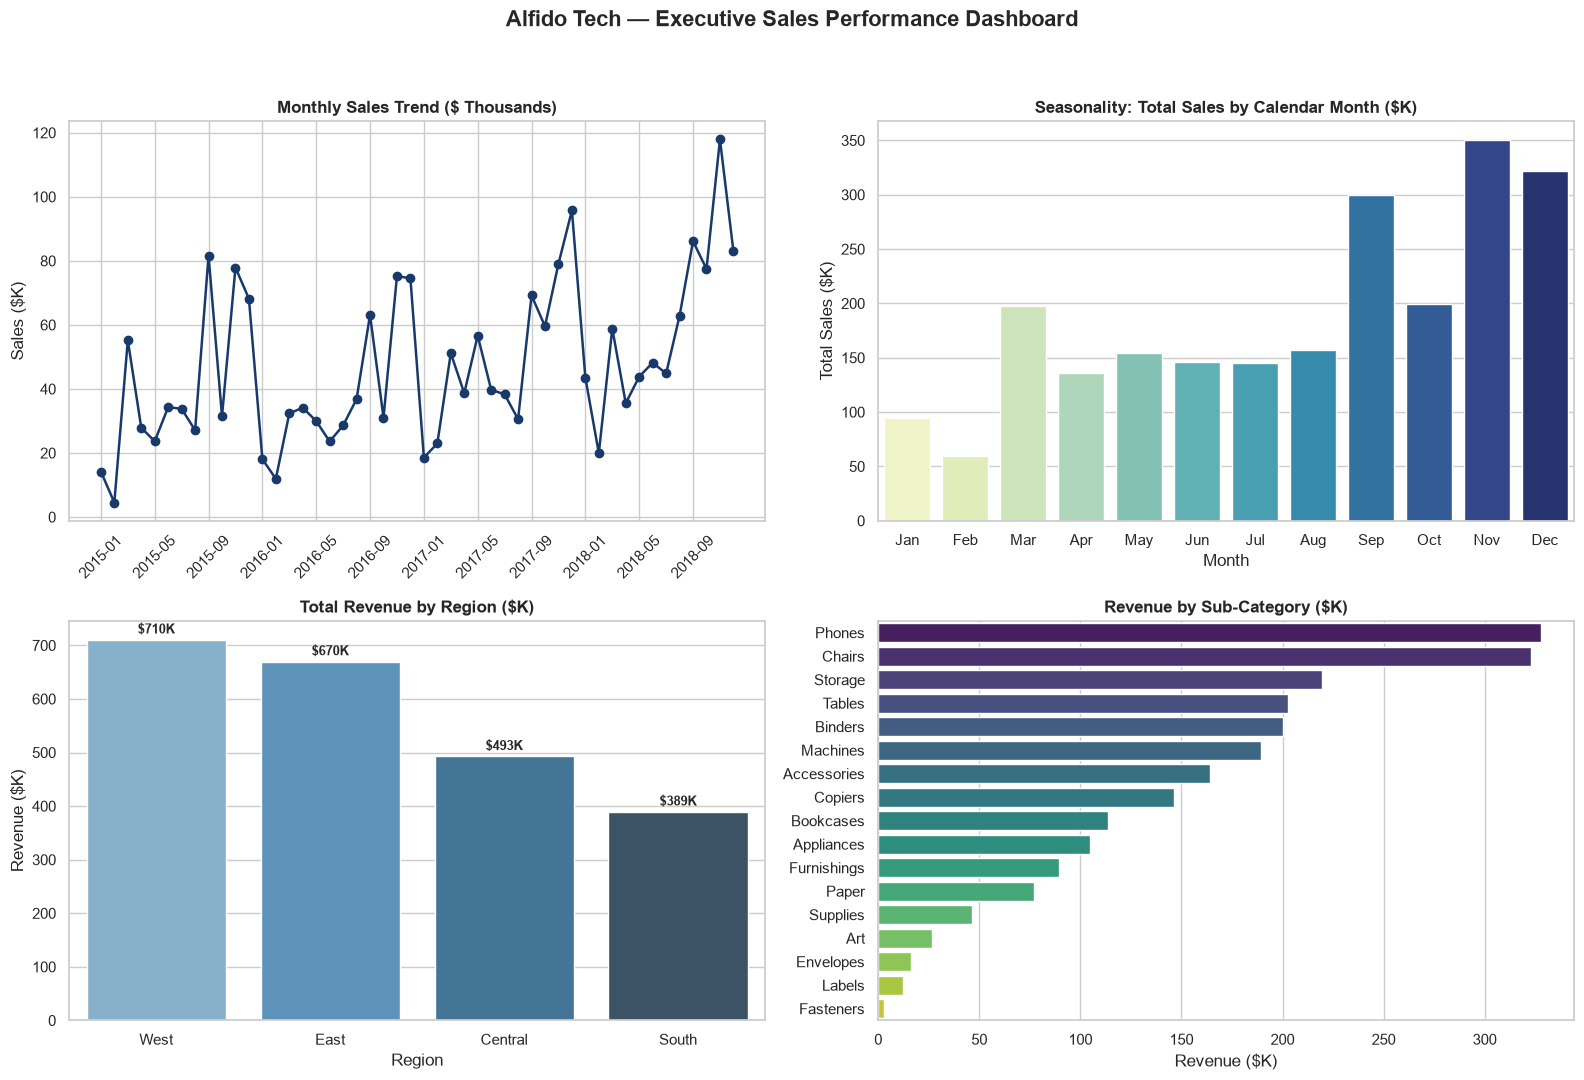

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
fig.suptitle("Alfido Tech — Executive Sales Performance Dashboard", fontsize=16, fontweight="bold", y=0.98)

# Panel 1: Monthly Sales Trend Over Time
monthly_trend = df.groupby("YearMonth")["Sales"].sum().reset_index()
axes[0, 0].plot(monthly_trend["YearMonth"], monthly_trend["Sales"] / 1e3, marker="o", linewidth=1.8, color="#183A6B")
axes[0, 0].set_title("Monthly Sales Trend ($ Thousands)", fontweight="bold")
axes[0, 0].set_ylabel("Sales ($K)")
axes[0, 0].set_xticks(range(0, len(monthly_trend), 4))
axes[0, 0].set_xticklabels(monthly_trend["YearMonth"].iloc[::4], rotation=45)

# Panel 2: Seasonality by Month (Aggregated Across All Years)
sns.barplot(data=monthly_seasonality, x="Month_Name", y=monthly_seasonality["Sales"] / 1e3, ax=axes[0, 1], hue="Month_Name", palette="YlGnBu", legend=False)
axes[0, 1].set_title("Seasonality: Total Sales by Calendar Month ($K)", fontweight="bold")
axes[0, 1].set_xlabel("Month")
axes[0, 1].set_ylabel("Total Sales ($K)")

# Panel 3: Regional Sales Performance
sns.barplot(x=region_summary.index, y=region_summary["Revenue"] / 1e3, ax=axes[1, 0], hue=region_summary.index, palette="Blues_d", legend=False)
axes[1, 0].set_title("Total Revenue by Region ($K)", fontweight="bold")
axes[1, 0].set_xlabel("Region")
axes[1, 0].set_ylabel("Revenue ($K)")
for i, val in enumerate(region_summary["Revenue"] / 1e3):
    axes[1, 0].text(i, val + 12, f"${val:,.0f}K", ha="center", fontsize=9, fontweight="bold")

# Panel 4: Sub-Category Revenue Ranking
top_sub = subcat_summary["Revenue"] / 1e3
sns.barplot(y=top_sub.index, x=top_sub.values, ax=axes[1, 1], hue=top_sub.index, palette="viridis", legend=False)
axes[1, 1].set_title("Revenue by Sub-Category ($K)", fontweight="bold")
axes[1, 1].set_xlabel("Revenue ($K)")
axes[1, 1].set_ylabel("")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.savefig("chart_sales_dashboard.png", dpi=300)
plt.show()

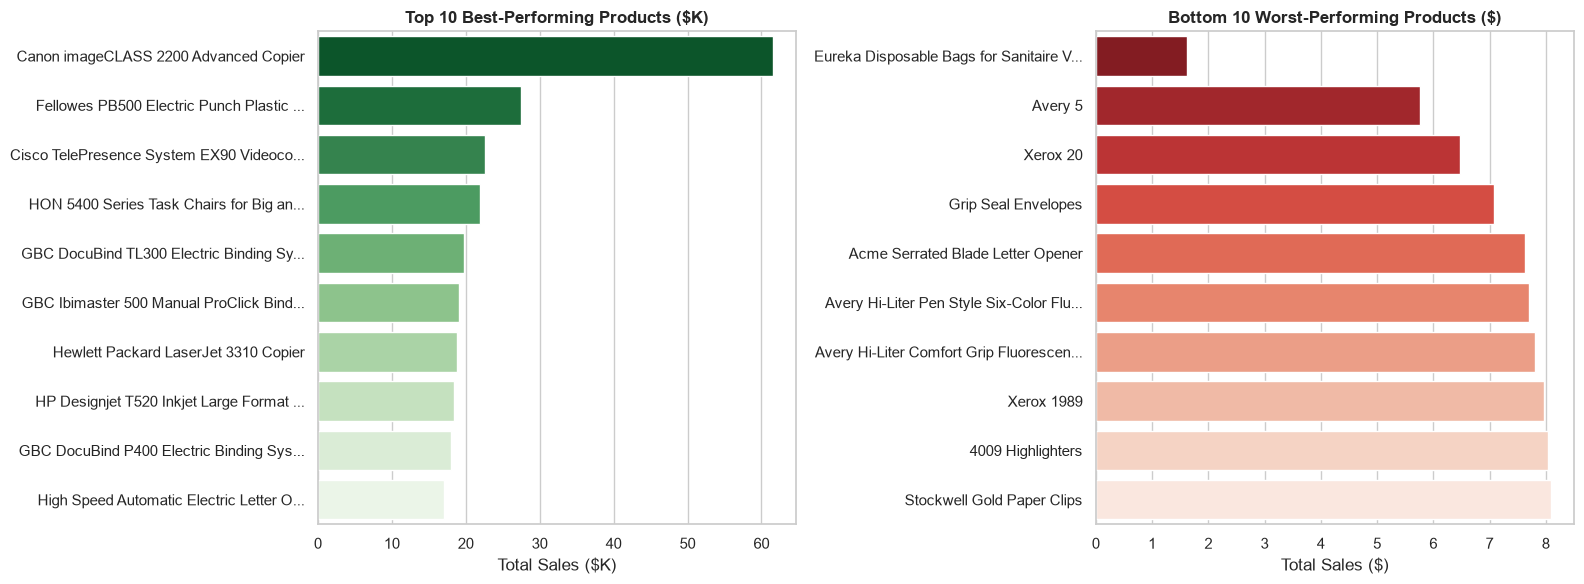

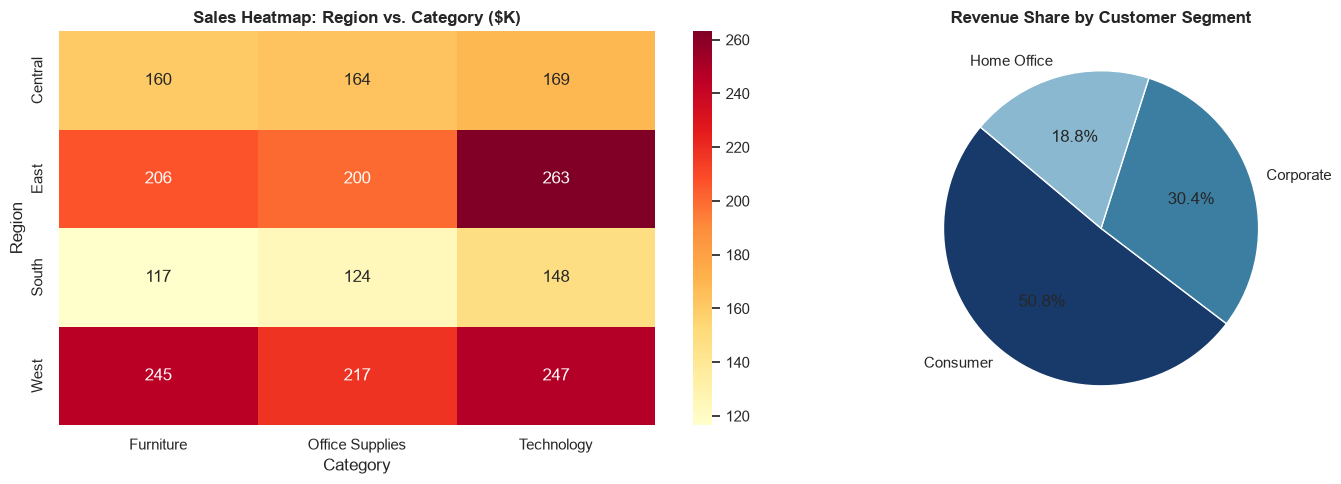

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Shorten long product names cleanly for plotting
top_labels = [p[:38] + "..." if len(p) > 38 else p for p in top10_products.index]
bot_labels = [p[:38] + "..." if len(p) > 38 else p for p in bottom10_products.index]

# 1. Top 10 Products
sns.barplot(y=top_labels, x=top10_products.values / 1e3, ax=axes[0], hue=top_labels, palette="Greens_r", legend=False)
axes[0].set_title("Top 10 Best-Performing Products ($K)", fontweight="bold")
axes[0].set_xlabel("Total Sales ($K)")

# 2. Bottom 10 Products
sns.barplot(y=bot_labels, x=bottom10_products.values, ax=axes[1], hue=bot_labels, palette="Reds_r", legend=False)
axes[1].set_title("Bottom 10 Worst-Performing Products ($)", fontweight="bold")
axes[1].set_xlabel("Total Sales ($)")

plt.tight_layout()
plt.savefig("chart_best_worst_products.png", dpi=300)
plt.show()

# Additional Chart: Category x Region Heatmap + Segment Share
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

reg_cat_pivot = df.pivot_table(values="Sales", index="Region", columns="Category", aggfunc="sum") / 1e3
sns.heatmap(reg_cat_pivot, annot=True, fmt=",.0f", cmap="YlOrRd", ax=axes[0])
axes[0].set_title("Sales Heatmap: Region vs. Category ($K)", fontweight="bold")

axes[1].pie(seg_summary["Revenue"], labels=seg_summary.index, autopct="%1.1f%%", startangle=140, colors=["#183A6B", "#3B7EA1", "#8AB8D0"])
axes[1].set_title("Revenue Share by Customer Segment", fontweight="bold")

plt.tight_layout()
plt.savefig("chart_region_category_segment.png", dpi=300)
plt.show()

In [8]:
from fpdf import FPDF

class SalesReport(FPDF):
    def header(self):
        if self.page_no() > 1:
            self.set_font("Helvetica", "I", 8)
            self.set_text_color(110, 110, 110)
            self.cell(0, 8, "Alfido Tech | Task 2: Sales Performance Analysis Report", align="R", new_x="LMARGIN", new_y="NEXT")
            self.ln(2)

    def footer(self):
        self.set_y(-15)
        self.set_font("Helvetica", "I", 8)
        self.set_text_color(120, 120, 120)
        self.cell(0, 10, f"Page {self.page_no()}", align="C")

    def section_title(self, title):
        self.set_font("Helvetica", "B", 13)
        self.set_text_color(24, 58, 107)
        self.cell(0, 9, title, new_x="LMARGIN", new_y="NEXT")
        self.set_draw_color(24, 58, 107)
        self.line(15, self.get_y(), 195, self.get_y())
        self.ln(4)

    def body_text(self, text):
        self.set_font("Helvetica", "", 10)
        self.set_text_color(40, 40, 40)
        self.multi_cell(0, 5.5, text)
        self.ln(2)

# GitHub repository folder link for Task 2
github_url = "https://github.com/ninaweaniket6-design/Alfido-Tech-Data-Analytics-Internship/tree/main/Task2_Sales_Performance"

# Pull exact live values from Cells 2 & 3
top_region = region_summary.index[0]
top_region_rev = region_summary.iloc[0]["Revenue"] / 1e3
low_region = region_summary.index[-1]
low_region_rev = region_summary.iloc[-1]["Revenue"] / 1e3
top2_reg_share = region_summary.iloc[:2]["Revenue_Share_Pct"].sum()

top_cat = cat_summary.index[0]
top_cat_share = cat_summary.iloc[0]["Revenue_Share_Pct"]
top_sub1, top_sub2 = subcat_summary.index[0], subcat_summary.index[1]
low_sub1, low_sub2 = subcat_summary.index[-1], subcat_summary.index[-2]

top_prod_name = top10_products.index[0]
top_prod_rev = top10_products.iloc[0]
bot_prod_max = bottom10_products.max()

q4_share = (quarterly_sales["Q4"] / total_revenue) * 100
q1_share = (quarterly_sales["Q1"] / total_revenue) * 100
peak_month = monthly_seasonality.loc[monthly_seasonality["Sales"].idxmax(), "Month_Name"]
low_month = monthly_seasonality.loc[monthly_seasonality["Sales"].idxmin(), "Month_Name"]

cons_share = seg_summary.loc["Consumer", "Revenue_Share_Pct"]
corp_share = seg_summary.loc["Corporate", "Revenue_Share_Pct"]
home_share = seg_summary.loc["Home Office", "Revenue_Share_Pct"]

start_date = df["Order_Date"].min().strftime("%b %Y")
end_date = df["Order_Date"].max().strftime("%b %Y")
prev_yr, last_yr = yearly_sales.index[-2], yearly_sales.index[-1]

pdf = SalesReport()
pdf.set_auto_page_break(auto=True, margin=15)
pdf.set_margins(15, 15, 15)

# ================= PAGE 1: TITLE, CODE LINK, EXEC SUMMARY & CLEANING =================
pdf.add_page()
pdf.set_fill_color(24, 58, 107)
pdf.rect(0, 0, 210, 42, "F")
pdf.set_y(10)
pdf.set_font("Helvetica", "B", 20)
pdf.set_text_color(255, 255, 255)
pdf.cell(0, 10, "Sales Performance Analysis Report", align="L", new_x="LMARGIN", new_y="NEXT")
pdf.set_font("Helvetica", "", 11)
pdf.cell(0, 7, "Alfido Tech Data Analytics Internship - Task 2 | Prepared by Aniket Ninawe", align="L", new_x="LMARGIN", new_y="NEXT")

# Clickable GitHub Link
pdf.set_y(47)
pdf.set_font("Helvetica", "B", 9.5)
pdf.set_text_color(40, 40, 40)
pdf.cell(0, 5.5, "GitHub Code & Notebook Repository:", new_x="LMARGIN", new_y="NEXT")
pdf.set_font("Helvetica", "U", 8.5)
pdf.set_text_color(17, 85, 204)
pdf.cell(0, 5.5, github_url, link=github_url, new_x="LMARGIN", new_y="NEXT")
pdf.ln(4)

pdf.section_title("1. Executive Summary & Headline KPIs")
pdf.body_text(
    f"This report evaluates Superstore sales performance across {total_orders:,} orders ({total_items:,} line items) "
    f"and {unique_customers:,} unique customers from {start_date} to {end_date}. Total revenue reached ${total_revenue:,.2f} "
    f"with an order-level Average Order Value (AOV) of ${order_aov:,.2f}, a {repeat_cust_rate:.1f}% repeat customer rate, "
    f"and {yoy_latest:+.1f}% year-over-year revenue growth ({prev_yr} to {last_yr}). Performance is heavily concentrated "
    f"in Q4 ({q4_share:.1f}% of annual revenue), led by the {top_region} and East regions ({top2_reg_share:.1f}% combined share)."
)

# KPI Grid
pdf.set_fill_color(235, 241, 249)
kpis = [
    ("Total Revenue", f"${total_revenue/1e6:.2f}M", "Total Orders", f"{total_orders:,}"),
    ("Order-Level AOV", f"${order_aov:,.2f}", "Avg Line-Item Value", f"${avg_line_item:,.2f}"),
    ("Repeat Customer Rate", f"{repeat_cust_rate:.1f}%", f"YoY Growth ({prev_yr}->{last_yr})", f"{yoy_latest:+.1f}%"),
    ("Avg Shipping Time", f"{avg_ship_days:.2f} days", "Peak / Slowest Month", f"{peak_month} / {low_month}")
]
for k1, v1, k2, v2 in kpis:
    pdf.set_font("Helvetica", "B", 9.5)
    pdf.set_text_color(24, 58, 107)
    pdf.cell(45, 8, k1, border=1, fill=True)
    pdf.set_font("Helvetica", "", 9.5)
    pdf.set_text_color(30, 30, 30)
    pdf.cell(45, 8, v1, border=1)
    pdf.set_font("Helvetica", "B", 9.5)
    pdf.set_text_color(24, 58, 107)
    pdf.cell(45, 8, k2, border=1, fill=True)
    pdf.set_font("Helvetica", "", 9.5)
    pdf.set_text_color(30, 30, 30)
    pdf.cell(45, 8, v2, border=1, new_x="LMARGIN", new_y="NEXT")
pdf.ln(5)

pdf.section_title("2. Data Cleaning, Preparation & Schema Notes")
pdf.body_text(
    "- Encoding & Deduplication: Loaded the dataset with Latin-1 fallback encoding and verified 0 exact duplicate rows.\n"
    "- Missing Value Resolution: Identified 11 missing Postal_Code records (Burlington, Vermont), imputed them with 05401, and zero-padded all postal codes to 5 digits (0 missing values remaining).\n"
    "- Date Parsing & Feature Engineering: Parsed DD/MM/YYYY Order_Date and Ship_Date fields using dayfirst=True; engineered Year, Quarter, Month, YearMonth, and Shipping_Days (verified 0 negative lead times).\n"
    "- Metric Scope Note: Because Profit and digital funnel conversion columns are absent from this CSV schema, AOV was accurately aggregated at the unique Order_ID level alongside YoY growth, repeat-order rate, and fulfillment speed."
)

# ================= PAGE 2: REGIONAL PERFORMANCE & EXECUTIVE DASHBOARD =================
pdf.add_page()
pdf.section_title("3. Regional Performance & Seasonality Dashboard")
pdf.body_text(
    f"The {top_region} (${top_region_rev:,.0f}K) and East regions generate {top2_reg_share:.1f}% of total sales, whereas "
    f"the {low_region} lags at ${low_region_rev:,.0f}K. Seasonality is pronounced: Q4 contributes {q4_share:.1f}% of all "
    f"revenue (peaking in {peak_month}), while Q1 contributes just {q1_share:.1f}% (bottoming out in {low_month})."
)

# Regional Table
cols = ["Region", "Revenue ($)", "Rev Share", "Orders", "Customers", "Order AOV", "Avg Ship"]
widths = [28, 32, 24, 22, 24, 26, 24]
pdf.set_font("Helvetica", "B", 8.5)
pdf.set_fill_color(24, 58, 107)
pdf.set_text_color(255, 255, 255)
for col, w in zip(cols, widths):
    pdf.cell(w, 8, col, border=1, align="C", fill=True)
pdf.ln()

pdf.set_font("Helvetica", "", 8.5)
pdf.set_text_color(30, 30, 30)
for idx, (reg, row) in enumerate(region_summary.iterrows()):
    fill = idx % 2 == 1
    pdf.set_fill_color(245, 248, 252)
    vals = [
        str(reg),
        f"${row['Revenue']:,.0f}",
        f"{row['Revenue_Share_Pct']:.1f}%",
        f"{int(row['Orders']):,}",
        f"{int(row['Customers']):,}",
        f"${row['AOV']:,.2f}",
        f"{row['Avg_Ship_Days']:.2f}d"
    ]
    for i, (val, w) in enumerate(zip(vals, widths)):
        align = "L" if i == 0 else "R"
        pdf.cell(w, 7, val, border=1, align=align, fill=fill)
    pdf.ln()

pdf.ln(5)
pdf.image("chart_sales_dashboard.png", x=17, w=176)
pdf.ln(1)
pdf.set_font("Helvetica", "I", 8.5)
pdf.set_text_color(90, 90, 90)
pdf.cell(0, 5, "Figure 1: Executive Sales Dashboard covering monthly trend, seasonality, regional revenue, and sub-category ranking.", align="C", new_x="LMARGIN", new_y="NEXT")

# ================= PAGE 3: BEST/WORST PRODUCTS & SEGMENT MIX =================
pdf.add_page()
pdf.section_title("4. Best vs. Worst Products & Segment Breakdown")
pdf.body_text(
    f"Revenue is heavily top-loaded: '{top_prod_name}' alone generated ${top_prod_rev:,.0f} - more than double the second-best SKU - "
    f"while {top_sub1} and {top_sub2} lead all sub-categories. Conversely, all 10 worst-performing SKUs generated under "
    f"${bot_prod_max:.2f} each (dominated by low-ticket items in {low_sub1} and {low_sub2})."
)
pdf.image("chart_best_worst_products.png", w=180)
pdf.ln(4)

pdf.body_text(
    f"Across customer segments, Consumer accounts for {cons_share:.1f}% of revenue, Corporate for {corp_share:.1f}%, "
    f"and Home Office for {home_share:.1f}%. {top_cat} leads category share ({top_cat_share:.1f}%), with East and West "
    f"showing the strongest category density while South underperforms across every category."
)
pdf.image("chart_region_category_segment.png", w=180)

# ================= PAGE 4: 5 TACTICAL IMPROVEMENTS =================
pdf.add_page()
pdf.section_title("5. Five Tactical Improvements for Alfido Tech's Sales & Offerings")
pdf.body_text("To translate these findings into higher revenue velocity and balanced regional growth, Alfido Tech should implement five tactical actions:")

recs = [
    (
        f"1. Counter Q1 Slump ({low_month} Dip) with Targeted Off-Peak Promotions",
        f"Since Q4 generates {q4_share:.1f}% of annual revenue while Q1 drops to {q1_share:.1f}% (lowest in {low_month}), "
        f"launch 'New Year Workspace Upgrade' bundles and early-bird corporate procurement discounts in January-February "
        f"to smooth cash flow and lift Q1 order volume."
    ),
    (
        f"2. Run Regional Growth Campaigns in Underperforming {low_region} & Central Markets",
        f"The {low_region} (${low_region_rev:,.0f}K) trails the {top_region} (${top_region_rev:,.0f}K) by nearly half across "
        f"all three categories. Deploy localized ad spend, regional distributor partnerships, and free-shipping thresholds "
        f"specifically in South and Central states to capture untapped market share."
    ),
    (
        f"3. Rationalize Long-Tail SKUs & Bundle Slow Movers ({low_sub1}, {low_sub2})",
        f"The bottom 10 products contribute less than ${bot_prod_max:.2f} each in lifetime sales, adding catalog and inventory "
        f"overhead. Prune non-essential low-ticket SKUs or bundle consumables ({low_sub1}, {low_sub2}, Art) as low-friction "
        f"add-ons to high-volume {top_sub1} and {top_sub2} orders."
    ),
    (
        "4. Expand High-Value B2B Offerings for Corporate & Home Office Segments",
        f"While Consumer drives {cons_share:.1f}% of revenue, Corporate ({corp_share:.1f}%) and Home Office ({home_share:.1f}%) "
        f"represent high-AOV expansion opportunities. Offer volume-tiered pricing, dedicated account quotes, and recurring "
        f"supply subscriptions around top-selling copiers, chairs, and office tech."
    ),
    (
        "5. Pre-Position Inventory Ahead of the Sep-Dec Surge & Instrument Profit Tracking",
        f"Stock high-velocity {top_sub1}, {top_sub2}, and flagship copiers ahead of the September-December peak to protect "
        f"the {avg_ship_days:.1f}-day average shipping lead time. Simultaneously, capture unit cost, discount, and margin "
        f"fields in the ERP/order pipeline so Alfido Tech can optimize profitability alongside top-line sales."
    )
]

for title, desc in recs:
    pdf.set_font("Helvetica", "B", 10.5)
    pdf.set_text_color(24, 58, 107)
    pdf.cell(0, 7, title, new_x="LMARGIN", new_y="NEXT")
    pdf.set_font("Helvetica", "", 10)
    pdf.set_text_color(40, 40, 40)
    pdf.multi_cell(0, 5.5, desc)
    pdf.ln(3)

output_pdf = "Alfido_Tech_Task2_Sales_Performance_Report.pdf"
pdf.output(output_pdf)
print(f"PDF Report successfully generated: {output_pdf}")

PDF Report successfully generated: Alfido_Tech_Task2_Sales_Performance_Report.pdf
